In [1]:
import zarr
import gcsfs

fs = gcsfs.GCSFileSystem(token="anon")

gust_store = fs.get_mapper("gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3/instantaneous_10m_wind_gust")
gust_arr = zarr.open(gust_store, mode="r")
print("shape:", gust_arr.shape, "chunks:", gust_arr.chunks, "dtype:", gust_arr.dtype)

lat_store = fs.get_mapper("gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3/latitude")
lon_store = fs.get_mapper("gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3/longitude")
time_store = fs.get_mapper("gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3/time")

lat_arr = zarr.open(lat_store, mode="r")
lon_arr = zarr.open(lon_store, mode="r")
time_arr = zarr.open(time_store, mode="r")
print("lat shape:", lat_arr.shape, "lon shape:", lon_arr.shape, "time shape:", time_arr.shape)


shape: (1323648, 721, 1440) chunks: (1, 721, 1440) dtype: float32
lat shape: (721,) lon shape: (1440,) time shape: (1323648,)


In [2]:
import numpy as np

lat_vals = lat_arr[:]
lon_vals = lon_arr[:]
time_vals = time_arr[:]

print(lat_vals[:5], lat_vals[-5:])
print(lon_vals[:5], lon_vals[-5:])
print(time_vals[:5], time_arr.attrs.asdict())


[90.   89.75 89.5  89.25 89.  ] [-89.   -89.25 -89.5  -89.75 -90.  ]
[0.   0.25 0.5  0.75 1.  ] [358.75 359.   359.25 359.5  359.75]
[0 1 2 3 4] {'_ARRAY_DIMENSIONS': ['time'], 'calendar': 'proleptic_gregorian', 'units': 'hours since 1900-01-01 00:00:00'}


time_vals matches arange: True
lat_idx range: 236 244 lon_idx range: 1098 1106
time_idx range: 1041120 1041168 count: 49
subset shape: (49, 9, 9) max gust (m/s): 37.67621
peak gust time (UTC): 2018-10-10 15:00:00 value (m/s): 37.67621


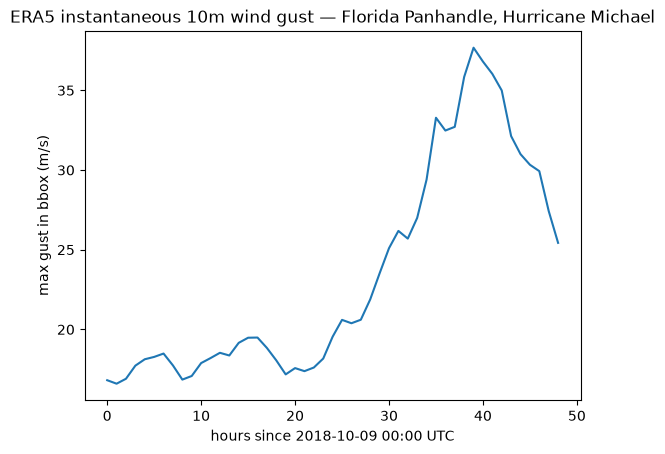

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Florida Panhandle, Hurricane Michael landfall ~2018-10-10 17:30 UTC near Mexico Beach, FL
lat_min, lat_max = 29.0, 31.0
lon_min_360, lon_max_360 = 274.5, 276.5  # -85.5 to -83.5 in 0-360 format

lat_idx = np.where((lat_vals <= lat_max) & (lat_vals >= lat_min))[0]
lon_idx = np.where((lon_vals >= lon_min_360) & (lon_vals <= lon_max_360))[0]

t0 = pd.Timestamp("1900-01-01")
start_hr = int((pd.Timestamp("2018-10-09 00:00:00") - t0).total_seconds() // 3600)
end_hr = int((pd.Timestamp("2018-10-11 00:00:00") - t0).total_seconds() // 3600)

time_idx = np.where((np.arange(len(time_vals)) >= start_hr) & (np.arange(len(time_vals)) <= end_hr))[0]
# time_vals should just be 0..N-1 as integer hour offsets - sanity check:
print("time_vals matches arange:", np.array_equal(time_vals[:10], np.arange(10)))
print("lat_idx range:", lat_idx.min(), lat_idx.max(), "lon_idx range:", lon_idx.min(), lon_idx.max())
print("time_idx range:", time_idx.min(), time_idx.max(), "count:", len(time_idx))

gust_sub = gust_arr[time_idx.min():time_idx.max()+1, lat_idx.min():lat_idx.max()+1, lon_idx.min():lon_idx.max()+1]
print("subset shape:", gust_sub.shape, "max gust (m/s):", np.nanmax(gust_sub))

peak_idx = np.unravel_index(np.nanargmax(gust_sub), gust_sub.shape)
peak_time = pd.Timestamp("1900-01-01") + pd.Timedelta(hours=int(time_idx.min() + peak_idx[0]))
print("peak gust time (UTC):", peak_time, "value (m/s):", gust_sub[peak_idx])

plt.plot(gust_sub.max(axis=(1,2)))
plt.xlabel("hours since 2018-10-09 00:00 UTC")
plt.ylabel("max gust in bbox (m/s)")
plt.title("ERA5 instantaneous 10m wind gust — Florida Panhandle, Hurricane Michael")
plt.savefig("../data/raw/era5_gust_michael.png", dpi=150)
plt.show()
